In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy.signal import detrend
import numpy as np

def my_find_nearest(ar,target):
    index = (np.abs(ar - target)).argmin()
    return index


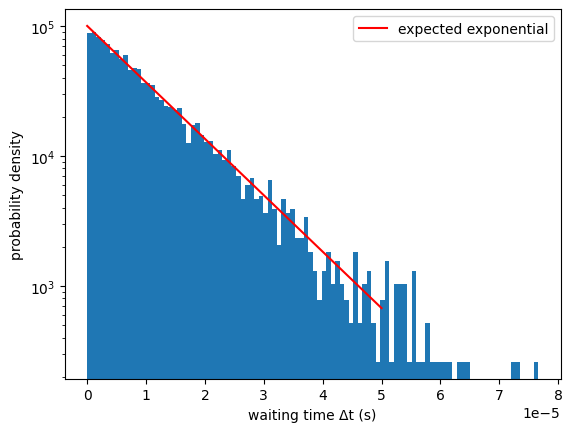

In [2]:
# Straigh-up completely vectorized, all events          
def difference_matrix(a):
    x = np.reshape(a, (len(a), 1))
    return x - x.transpose()     
    
lam = 0.1e6           # 100 kHz
T_total = 0.05        # simulate 1 s
rng = np.random.default_rng()

# generate exponential waiting times
n_events_est = int(T_total * lam * 1.2)  # rough upper bound
waiting_times = rng.exponential(scale=1/lam, size=n_events_est) # + 
timestamps = np.cumsum(waiting_times)
timestamps = timestamps[timestamps < T_total]  # crop to window
waiting_times = np.diff(timestamps)

plt.hist(waiting_times, bins=100, density=True)
t = np.linspace(0, 5/lam, 200)
plt.semilogy(t, lam * np.exp(-lam * t), 'r', label='expected exponential')
plt.xlabel("waiting time Δt (s)")
plt.ylabel("probability density")
plt.legend()
plt.show()

# plt.scatter(timestamps, np.ones_like(timestamps), s = 0.4)
# plt.show()

######## DO THE COMPLETE DIFFERENCE MATRIX CALCULATION
# diffs = difference_matrix(timestamps).flatten()
# diffs_hist, bins = np.histogram(diffs, bins=nbins)
# plt.scatter(bins[int(len(bins)/2)+1:-1],detrend(diffs_hist[int(len(bins)/2)+1:], type='linear') /np.max(diffs_hist) ,label=r"$\tau >0$")
# plt.scatter(-bins[:int(len(bins)/2)],detrend(diffs_hist[:int(len(bins)/2)], type='linear') /np.max(diffs_hist) ,label=r"$\tau <0$")
# plt.legend()
# plt.scatter(bins[int(len(bins)/2):-1],diffs_hist[int(len(bins)/2):] )

# plt.title("Detrended histogram of all time differences")
# plt.show()

In [3]:
# Using my loop correlator: 

# Also extremely costly! 
def correlate_dummy(ts, tmax, histogram, binning):  
    for photon1idx in range(ts.shape[0]):
        if photon1idx % 100==0:
            print(photon1idx/ ts.shape[0])
        for photon2idx in range(ts.shape[0]):
            if np.abs(ts[photon2idx] - ts[photon1idx]) < tmax*1.1 and photon1idx != photon2idx:  
                binidx = int((timestamps[photon2idx] - timestamps[photon1idx]) // binning + int(histogram.size/2))
                if binidx < histogram.size and  binidx >= 0:
                    histogram[binidx] += 1


    
tau_max = 1e-3
binning = 1e-11
taus = np.arange(-tau_max, tau_max, binning)

histogram_loop = np.zeros_like(taus)

correlate_dummy(timestamps, tau_max , histogram_loop, binning)

0.0
0.019932230416583617
0.039864460833167234
0.059796691249750844
0.07972892166633447
0.09966115208291808
0.11959338249950169
0.1395256129160853
0.15945784333266894
0.17939007374925253
0.19932230416583616
0.21925453458241978
0.23918676499900338
0.25911899541558703
0.2790512258321706
0.2989834562487542
0.31891568666533787
0.33884791708192147
0.35878014749850506
0.3787123779150887
0.3986446083316723
0.4185768387482559
0.43850906916483956
0.45844129958142316
0.47837352999800675
0.4983057604145904
0.5182379908311741
0.5381702212477576
0.5581024516643412
0.5780346820809249
0.5979669124975084
0.6178991429140921
0.6378313733306757
0.6577636037472593
0.6776958341638429
0.6976280645804266
0.7175602949970101
0.7374925254135938
0.7574247558301774
0.777356986246761
0.7972892166633446
0.8172214470799283
0.8371536774965118
0.8570859079130955
0.8770181383296791
0.8969503687462627
0.9168825991628463
0.93681482957943
0.9567470599960135
0.9766792904125972
0.9966115208291808


(-10.0, 10.0)

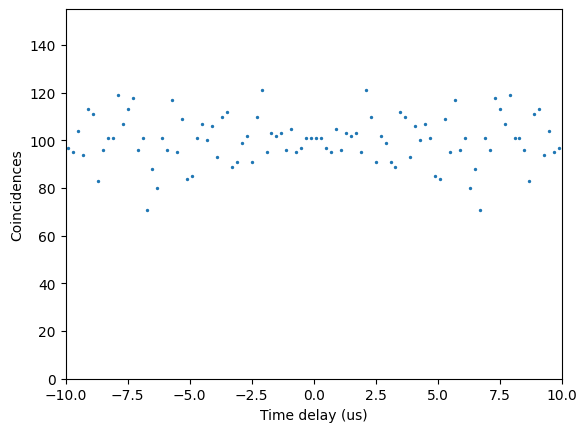

In [8]:
n_new_bins_approx = int(1e4)
tau_rebin, h_rebin = re_bin(taus*1e12, histogram_loop, n_new_bins_approx)
plt.scatter(tau_rebin/1e6, h_rebin, s = 2)
plt.ylim(0,np.max(h_rebin)*1.1)
plt.xlabel("Time delay (us)")
plt.ylabel("Coincidences")
plt.xlim(-10,10)

In [36]:
# A slightly more efficient method: 
max_ram_per_worker = 0.3e9 # 0.8 GB per worker
chunksize = len(timestamps)


def correlate_numpy_chunked_simple(ts, tmax, hist, nbins, block_size= int(max_ram_per_worker / (8* chunksize))):
    ts = ts.astype(np.float64) #change this to int64 on G13 lab PC 
    N = ts.size
    for i0 in range(0, N, block_size):
        if i0%100==0:
            print(i0/N)
        i1 = min(N, i0 + block_size)
        block = ts[i0:i1]
        diffs = block[:, None] - ts[None, :] # time delay between block of timestamps and all timestamps together
        mask = (np.abs(diffs) < tmax) & (diffs != 0) # look at identity matrix instead
        sel = diffs[mask]
        h, _ = np.histogram(sel,range = (-tmax, tmax), bins=nbins)
        hist += h
    

tau_max = 1e-3
binning = 1e-7
taus = np.arange(-tau_max, tau_max, binning)

# binning = T_total/1000
# tau_max = np.max(timestamps)/10
taus = np.arange(-tau_max, tau_max, binning)
nbins = len(taus)
histogram_blocks = np.zeros_like(taus)
# correlate_numpy_chunked_simple(timestamps, tau_max, histogram_blocks, nbins)

In [2]:
# plt.scatter(taus[taus>0], detrend(histogram_blocks[taus>0],type='linear')/np.max(histogram_blocks),label=r"$\tau >0$")
# plt.scatter(-taus[taus<0], detrend(histogram_blocks[taus<0],type='linear')/np.max(histogram_blocks),label=r"$\tau <0$")

def re_bin(tau_bins, h, n_new_bins_approx):
    
    n_original_bins = len(tau_bins)
    len_new_bins = n_original_bins // n_new_bins_approx
    n_new_bins = n_original_bins//len_new_bins           # to make sure we bin cleanly
    
    tau_rebin = np.zeros(n_new_bins,dtype = np.int64)
    h_rebin   = np.zeros(n_new_bins,dtype = np.int64)
    
    for n in range(n_new_bins):
        tau_rebin[n] = np.sum( tau_bins[ n*len_new_bins : (n+1)*len_new_bins ] ) // len_new_bins
        h_rebin  [n] = np.sum( h       [ n*len_new_bins : (n+1)*len_new_bins ] )
    

    return tau_rebin, h_rebin

# n_new_bins_approx = int(1e4)
# tau_rebin, h_rebin = re_bin(taus*1e12, histogram_blocks, n_new_bins_approx)
# plt.scatter(tau_rebin/1e6, h_rebin, s = 2)
# plt.ylim(0,np.max(h_rebin)*1.1)
# plt.xlabel("Time delay (us)")
# plt.ylabel("Coincidences")
# plt.xlim(-10,10)


# print("Total photon events : ", timestamps.size/1e6, " million")
# print("Total accounted photon coincidences : ", np.sum(h_rebin)/1e6, " million")
# print("Total possible photon coincidences : ", timestamps.size**2/1e6, " million")
# print("Ratio of 2*tmax vs ttot: ", 2*tau_max / T_total, " and coinc_meas / coinc_all ", np.sum(h_rebin)/timestamps.size**2)


In [18]:
# Testing now with two separate detectors

# Workflow for remote analysis


def timestamps_select_channels(timestamps, detector, mode):
    if mode == "X01":
        ts1 = timestamps[detector == 0]   # reference (start)
        ts2 = timestamps[detector == 1]   # correlated (stop)
    elif mode == "X10":
        ts1 = timestamps[detector == 1]
        ts2 = timestamps[detector == 0]
    elif mode == "A0":
        ts1 = ts2 = timestamps[detector == 0]
    elif mode == "A1":
        ts1 = ts2 = timestamps[detector == 1]
    elif mode == "all":
        ts1 = ts2 = timestamps
    else:
        raise ValueError(f"Unknown mode {mode}")
    return ts1, ts2

def correlate_numpy_chunked(ts1, ts2, tmax, hist, nbins, block_size= 2000):
    ts1 = ts1.astype(np.float64)
    ts2 = ts2.astype(np.float64) # should make sure of this before opening the function
    N1 = ts1.size
    bins = np.linspace(-tmax, tmax, nbins + 1)

    for i0 in range(0, N1, block_size):
        if i0%100==0:
            print(i0/N1)
        i1 = min(N1, i0 + block_size)
        block = ts1[i0:i1]
        diffs = block[:, None] - ts2[None, :]
        mask = (np.abs(diffs) < tmax) & (diffs != 0)
        sel = diffs[mask]
        h, _ = np.histogram(sel, bins=bins)
        hist += h
    print(1)

In [ ]:
mode = "all"     
tau_max = 1e-3
binning = 1e-7
taus = np.arange(-tau_max, tau_max, binning)

nbins = len(taus)
histogram = np.zeros_like(taus)


gen = np.random.rand(len(timestamps))
detector = np.zeros_like(gen)
detector[gen>0.5] = 1

max_ram_per_worker = 0.3e9 # 0.8 GB per worker
chunksize = len(timestamps)
block_size = int(max_ram_per_worker / (8* chunksize))

ts1, ts2 = timestamps_select_channels(timestamps, detector, mode)
correlate_numpy_chunked(ts1, ts2, tau_max, histogram, nbins, block_size)

0.0


Total photon events :  0.005017  million
Total accounted photon coincidences :  0.997676  million
Total possible photon coincidences :  25.170289  million
Ratio of 2*tmax vs ttot:  0.04  and coinc_meas / coinc_all  0.03963704985667824


Text(0, 0.5, 'Coincidences')

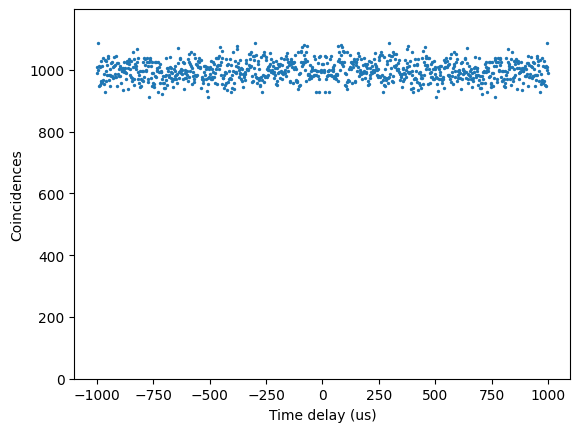

In [30]:
print("Total photon events : ", timestamps.size/1e6, " million")
print("Total accounted photon coincidences : ", np.sum(histogram)/1e6, " million")
print("Total possible photon coincidences : ", timestamps.size**2/1e6, " million")
print("Ratio of 2*tmax vs ttot: ", 2*tau_max / T_total, " and coinc_meas / coinc_all ", np.sum(histogram)/timestamps.size**2)

n_new_bins_approx = int(1e3)
tau_rebin, h_rebin = re_bin(taus*1e12, histogram, n_new_bins_approx)
plt.scatter(tau_rebin/1e6, h_rebin, s = 2)
plt.ylim(0,np.max(h_rebin)*1.1)
plt.xlabel("Time delay (us)")
plt.ylabel("Coincidences")
# plt.xlim(-10,10)

In [106]:
5/lam0*5

0.00025

# Testing bunching: 

In [29]:
# target mean rate and weak bunching strength
lam0   = 500        
contrast = 0.3     # 0 -> Poisson; small positive -> weak bunching
tau_c = 5     # bunching correlation time
T_total = 0.4*60*60 
dt = 1/lam0/100           # time grid (ensure lam*dt << 1)
print("Rate*sampling time",lam0*dt)
rng = np.random.default_rng(1)

# ----- build telegraph (two-state) rate trace -----
lam_low  = lam0*(1 - contrast)
lam_high = lam0*(1 + contrast)

n_steps = int(T_total/dt)
t = np.arange(n_steps)*dt

# simulate telegraph process by drawing exponential dwell times
lam_trace = np.empty(n_steps, dtype=float)
state = 0  # 0 -> low, 1 -> high
idx = 0
while idx < n_steps:
    dwell = rng.exponential(tau_c)
    steps = max(1, int(dwell/dt))
    end = min(n_steps, idx+steps)
    lam_trace[idx:end] = lam_low if state==0 else lam_high
    state ^= 1
    idx = end

p = lam_trace * dt
p = np.clip(p, 0, 0.1)     # safety: keep probabilities small
events = rng.uniform(size=n_steps) < p
timestamps = t[events]

Rate*sampling time 0.01


Time bins:  288.00569931398627 ms, num bins:  50000
Time bin size * num_bins:  14400.284965699315 s
N timestamps:  7198983


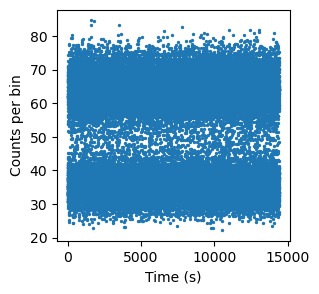

In [32]:
# plt.scatter(timestamps[:300], np.ones_like(timestamps[:300]), s = 2)
nbins = int(5e4)

time_bins = np.linspace(timestamps[0], timestamps[-1],nbins)
rate, time_bins = np.histogram(timestamps, bins = time_bins)
rate = rate.astype(float)
# # Randomize over long timescales
# t0 = 0
# mag0 = 10
# avg_timestep = 30
# for i in range(int(np.max(time_bins)*2/mag0)):
#     dt = np.random.rand()*avg_timestep
#     mag = np.random.rand()*mag0 - mag0/2
#     rate[(time_bins[:-1]<t0+dt) & (time_bins[:-1]>t0)] += mag
#     t0 += dt
print("Time bins: ",(time_bins[1]-time_bins[0])*1e3, "ms, num bins: ", nbins)
print("Time bin size * num_bins: ",(time_bins[1]-time_bins[0])*len(time_bins), "s")

plt.figure(figsize = (3,3))
plt.scatter(time_bins[:-1], rate/(time_bins[1]-time_bins[0])/10, s = 2)
# plt.xlim(0,10*60)
plt.xlabel("Time (s)")
plt.ylabel("Counts per bin")
print("N timestamps: ", len(timestamps))

In [7]:
# waiting times for plotting (not i.i.d. anymore!)
waiting_times = np.diff(timestamps)

# ----- plot waiting-time histogram vs exponential with mean 1/lam0 -----
bins = np.linspace(0, 10e-3, 100)
hist, bins = np.histogram(waiting_times, bins=bins)#, density=False, alpha=0.6, label="sim (bunched)")

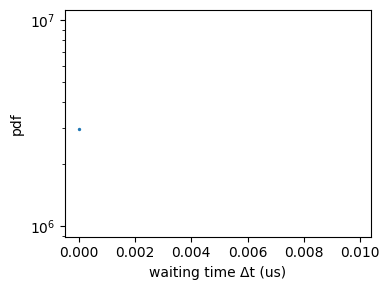

Total photon count:  2.95509  million


In [17]:
plt.figure(figsize= (4,3))
plt.yscale('log')
plt.scatter(bins[:-1], hist, s= 2)
# tt = np.linspace(0, 100e-6, 400)
# plt.plot(tt*1e6, lam0*np.exp(-lam0*tt)/1e6, 'r', lw=2, label='Poisson ref (exp)')
plt.xlabel("waiting time Δt (us)")
plt.ylabel("pdf")
# plt.legend()
plt.tight_layout()
plt.show()
print("Total photon count: ", np.sum(hist)/1e6," million")


In [34]:

mode = "all"     
tau_max = 10 # 100 us max time
binning = 100e-3
taus = np.arange(-tau_max, tau_max, binning)

nbins = len(taus)
histogram = np.zeros_like(taus)


gen = np.random.rand(len(timestamps))
detector = np.zeros_like(gen)
detector[gen>0.5] = 1

max_ram_per_worker = 0.4e9 # 0.8 GB per worker
chunksize = len(timestamps)
block_size = int(max_ram_per_worker / (8* chunksize))

ts1, ts2 = timestamps_select_channels(timestamps[:len(timestamps)], detector[:len(timestamps)], mode)
correlate_numpy_chunked(ts1, ts2, tau_max, histogram, nbins, block_size)


0.0
0.00041672570280789777
0.0008334514056157955
0.0012501771084236933
0.001666902811231591
0.002083628514039489
0.0025003542168473866
0.0029170799196552846
0.003333805622463182
0.00375053132527108
0.004167257028078978
0.004583982730886876
0.005000708433694773
0.005417434136502672
0.005834159839310569
0.006250885542118467
0.006667611244926364
0.007084336947734263
0.00750106265054216
0.007917788353350058
0.008334514056157956
0.008751239758965853
0.009167965461773751
0.00958469116458165
0.010001416867389546
0.010418142570197445
0.010834868273005343
0.01125159397581324
0.011668319678621138
0.012085045381429035
0.012501771084236933
0.012918496787044832


KeyboardInterrupt: 

Total photon events :  1.798014  million
Total accounted photon coincidences :  1741.712632  million
Total possible photon coincidences :  3232854.344196  million
Ratio of 2*tmax vs ttot:  0.005555555555555556  and coinc_meas / coinc_all  0.0005387538214107688


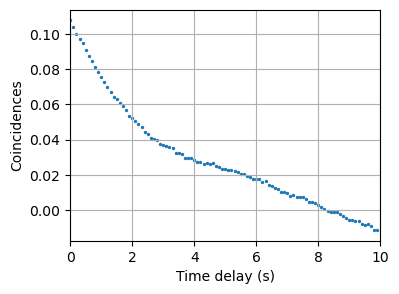

In [28]:

print("Total photon events : ", timestamps.size/1e6, " million")
print("Total accounted photon coincidences : ", np.sum(histogram)/1e6, " million")
print("Total possible photon coincidences : ", timestamps.size**2/1e6, " million")
print("Ratio of 2*tmax vs ttot: ", 2*tau_max / T_total, " and coinc_meas / coinc_all ", np.sum(histogram)/timestamps.size**2)
histo_filt = histogram[histogram>0]
n_mean = 30
histo_norm = (histo_filt - np.mean(histo_filt[-n_mean:-2]))/ np.mean(histo_filt[-n_mean:-2])
taus_filt = taus[histogram>0]
plt.figure(figsize= (4,3))
plt.scatter(taus_filt,histo_norm, s = 2)
# plt.scatter(taus, histogram, s= 2)

# plt.ylim(0,np.max(h_rebin)*1.1)
plt.xlabel("Time delay (s)")
plt.ylabel("Coincidences")
plt.xlim(0,10)
plt.grid()

# This is what the classical autocorrelator of this data would look like

Time bins:  0.10000189870464075 ms, num bins:  50000
Time bin size * num_bins:  5.000094935232037 s


Text(0, 0.5, 'Counts per bin')

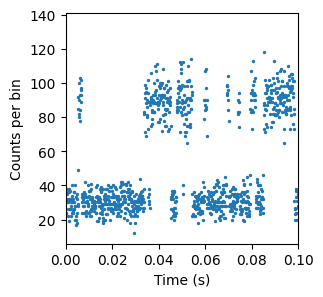

In [219]:
## AUTOCORRELATION OF THIS DATA -- want to reproduce tau_c = 100 ms

signal = (rate-np.mean(rate))
ac = np.correlate(signal, signal, mode='full')

l = np.arange(-len(signal)+1, len(signal)) * (time_bins[1] - time_bins[0]) # this in s


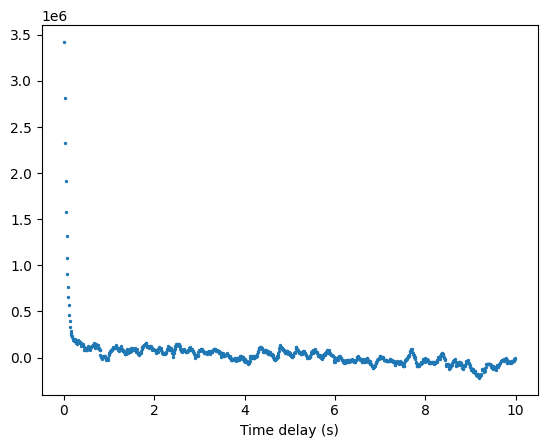

In [220]:
autocorr_range = [0,10] #

l_range = l[(l > autocorr_range[0]) & (l < autocorr_range[1])]
ac_range = ac[(l > autocorr_range[0]) & (l < autocorr_range[1])]
plt.scatter(l_range, ac_range-ac_range[-1], s= 2) # now plotting against seconds
plt.xlabel("Time delay (s)")
# plt.yscale('log')
# plt.xlim(0,0.5)
plt.show()

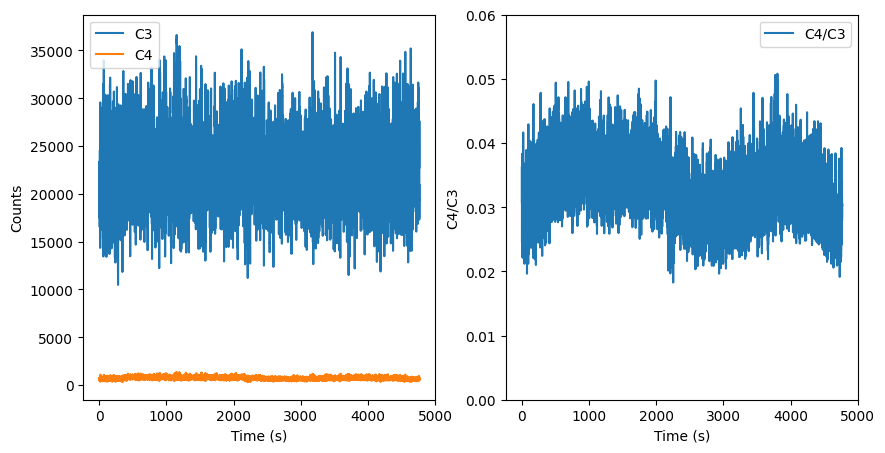

In [14]:
# Compare this to the Toptica measured in SYNC mode

# 1) toptica count rates in sync and 
import pandas as pd
from datetime import datetime

log_file_name = "/Users/kilian/Local Docs/Physik/PhD/Data Analysis/Data/Oct/toptica_sync_mode.txt" # close to transition


fig, ax = plt.subplots(1,2,figsize = (10,5))
df = pd.read_csv(log_file_name, sep=r"\t",skiprows=9, engine="python")

df = df[["C3", "C4", "T"]].copy()

df["T"] = pd.to_datetime(df["T"], format="%d-%b-%y %H:%M:%S.%f")


t0 = df["T"].iloc[0]
df["time_s"] = (df["T"] - t0).dt.total_seconds()

t = df["time_s"].to_numpy()
c3 = df["C3"].to_numpy()
c4 = df["C4"].to_numpy()

plt.sca(ax[0])
plt.plot(t, c3,label = "C3") # I know this is ~ 2e5 cts/s
plt.plot(t, c4,label = "C4")
plt.xlabel("Time (s)")
plt.ylabel("Counts")
plt.legend()
# plt.xlim(50,90)
plt.sca(ax[1])
plt.plot(t, c4/c3,label = "C4/C3")
plt.xlabel("Time (s)")
plt.ylabel("C4/C3")
plt.ylim(0,0.06)
plt.legend()



Probability of pile up for experiment:  0.03846153846153855


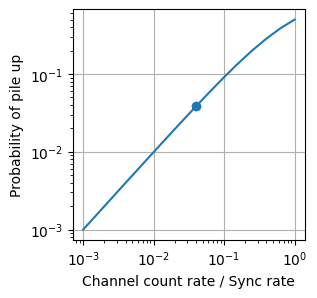

In [4]:
# Probability of having two channel photons within one sync cycle:
rho = 10**np.arange(-3,0.1,0.2)
p_pileup  = lambda  rho: 1 - 1 / (1 + rho)
plt.figure(figsize = (3,3))
plt.loglog(rho, p_pileup(rho))
plt.scatter(0.04,p_pileup(0.04))
plt.xlabel("Channel count rate / Sync rate")
plt.ylabel("Probability of pile up")
plt.grid()
print("Probability of pile up for experiment: ", p_pileup(0.04))

# Testing what an autocorrelation of some possible data looks like

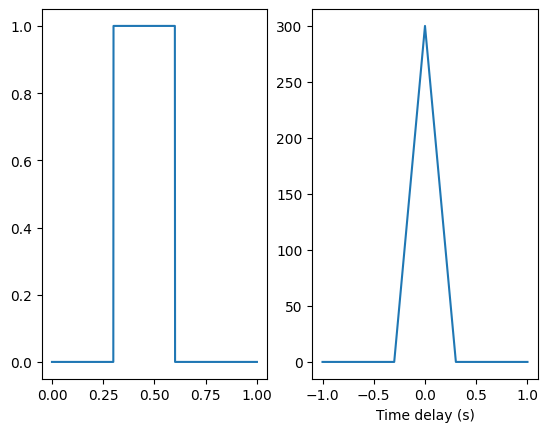

In [59]:
t = np.linspace(0,1,1000)
s = np.zeros_like(t)
s[(t>0.3) & (t<0.6)]= 1
fig, ax = plt.subplots(1,2)
plt.sca(ax[0])
plt.plot(t,s)
plt.sca(ax[1])

signal = s
ac = np.correlate(signal, signal, mode='full')
l = np.arange(-len(signal)+1, len(signal)) * (t[1] - t[0]) # this in s
plt.plot(l, ac) # now plotting against seconds
plt.xlabel("Time delay (s)")
plt.show()


In [3]:
import numpy as np
np.load(r"C:\Users\SSPDs\Documents\Offline SSPD Data\Reanalyzing PLE\20251027\chunks_B_-0.008V\histogramtest_chunk0_all.npy")

array([0, 0, 0, ..., 0, 0, 0], dtype=uint64)